In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns # For creating plots
import matplotlib.ticker as mtick # For specifying the axes tick format 
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
data = pd.read_csv("/Users/karthik/Downloads/Fraud_Analysis_Dataset.csv")


In [3]:
data.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,1,TRANSFER,181.0,C1305486145,181.0,0.0,C553264065,0.0,0.0,1
1,1,CASH_OUT,181.0,C840083671,181.0,0.0,C38997010,21182.0,0.0,1
2,1,TRANSFER,2806.0,C1420196421,2806.0,0.0,C972765878,0.0,0.0,1
3,1,CASH_OUT,2806.0,C2101527076,2806.0,0.0,C1007251739,26202.0,0.0,1
4,1,TRANSFER,20128.0,C137533655,20128.0,0.0,C1848415041,0.0,0.0,1


In [4]:
data.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
count,11142.000000,1.114200e+04,1.114200e+04,1.114200e+04,1.114200e+04,1.114200e+04,11142.000000
mean,8.717645,2.131915e+05,9.241173e+05,8.249576e+05,8.883541e+05,1.103211e+06,0.102495
std,16.067479,7.600650e+05,2.143004e+06,2.089894e+06,2.601376e+06,2.982447e+06,0.303312
min,1.000000,2.390000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,2.000000,4.946618e+03,4.270000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
50%,6.000000,1.676126e+04,2.816950e+04,4.420605e+03,0.000000e+00,0.000000e+00,0.000000
75%,7.000000,1.543366e+05,3.040855e+05,1.114126e+05,2.711555e+05,3.186374e+05,0.000000
max,95.000000,1.000000e+07,1.990000e+07,1.300000e+07,3.300000e+07,3.460000e+07,1.000000


In [5]:
data.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud'],
      dtype='object')

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11142 entries, 0 to 11141
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            11142 non-null  int64  
 1   type            11142 non-null  object 
 2   amount          11142 non-null  float64
 3   nameOrig        11142 non-null  object 
 4   oldbalanceOrg   11142 non-null  float64
 5   newbalanceOrig  11142 non-null  float64
 6   nameDest        11142 non-null  object 
 7   oldbalanceDest  11142 non-null  float64
 8   newbalanceDest  11142 non-null  float64
 9   isFraud         11142 non-null  int64  
dtypes: float64(5), int64(2), object(3)
memory usage: 870.6+ KB


In [7]:
data.dtypes

step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
dtype: object

In [8]:
data.isnull

<bound method DataFrame.isnull of        step      type     amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0         1  TRANSFER     181.00  C1305486145         181.00            0.00   
1         1  CASH_OUT     181.00   C840083671         181.00            0.00   
2         1  TRANSFER    2806.00  C1420196421        2806.00            0.00   
3         1  CASH_OUT    2806.00  C2101527076        2806.00            0.00   
4         1  TRANSFER   20128.00   C137533655       20128.00            0.00   
...     ...       ...        ...          ...            ...             ...   
11137     7     DEBIT    6393.71  C1331144930      433084.38       426690.68   
11138     7  CASH_OUT  298799.54   C932023579      426690.68       127891.14   
11139     7  CASH_OUT  423159.63    C61395726      127891.14            0.00   
11140     7   PAYMENT    1094.03  C1224570697       13918.00        12823.97   
11141     7   PAYMENT    9235.58  C1637966097       39963.00        30727.42   

     

In [9]:
data.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
dtype: int64

In [10]:
data.duplicated().sum()

0

In [11]:
df = data.copy()

In [12]:
df

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1
1,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.00,0.00,1
2,1,TRANSFER,2806.00,C1420196421,2806.00,0.00,C972765878,0.00,0.00,1
3,1,CASH_OUT,2806.00,C2101527076,2806.00,0.00,C1007251739,26202.00,0.00,1
4,1,TRANSFER,20128.00,C137533655,20128.00,0.00,C1848415041,0.00,0.00,1
...,...,...,...,...,...,...,...,...,...,...
11137,7,DEBIT,6393.71,C1331144930,433084.38,426690.68,C684896216,478421.00,210535.25,0
11138,7,CASH_OUT,298799.54,C932023579,426690.68,127891.14,C1761353343,704355.36,5270364.19,0
11139,7,CASH_OUT,423159.63,C61395726,127891.14,0.00,C1298316171,610479.00,749621.53,0
11140,7,PAYMENT,1094.03,C1224570697,13918.00,12823.97,M983553548,0.00,0.00,0


In [13]:
df_encoded = pd.get_dummies(df, columns=["type"], dtype=int)
print(df_encoded.head())

   step   amount     nameOrig  oldbalanceOrg  newbalanceOrig     nameDest  \
0     1    181.0  C1305486145          181.0             0.0   C553264065   
1     1    181.0   C840083671          181.0             0.0    C38997010   
2     1   2806.0  C1420196421         2806.0             0.0   C972765878   
3     1   2806.0  C2101527076         2806.0             0.0  C1007251739   
4     1  20128.0   C137533655        20128.0             0.0  C1848415041   

   oldbalanceDest  newbalanceDest  isFraud  type_CASH_IN  type_CASH_OUT  \
0             0.0             0.0        1             0              0   
1         21182.0             0.0        1             0              1   
2             0.0             0.0        1             0              0   
3         26202.0             0.0        1             0              1   
4             0.0             0.0        1             0              0   

   type_DEBIT  type_PAYMENT  type_TRANSFER  
0           0             0              

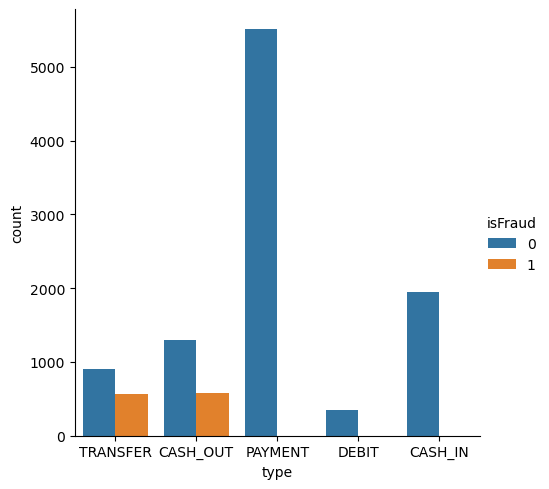

In [14]:
ax1 = sns.catplot(x="type", kind="count", hue="isFraud", data=df,
                  estimator=lambda x: sum(x==0)*100.0/len(x))

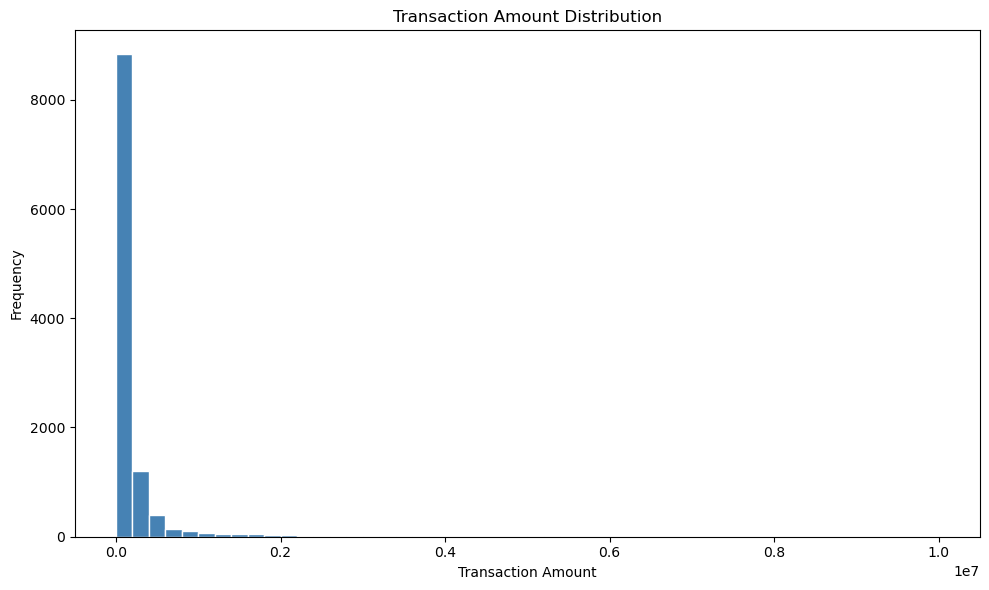

In [15]:
plt.figure(figsize=(10, 6))
plt.hist(df["amount"], bins=50, color="steelblue", edgecolor="white")

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

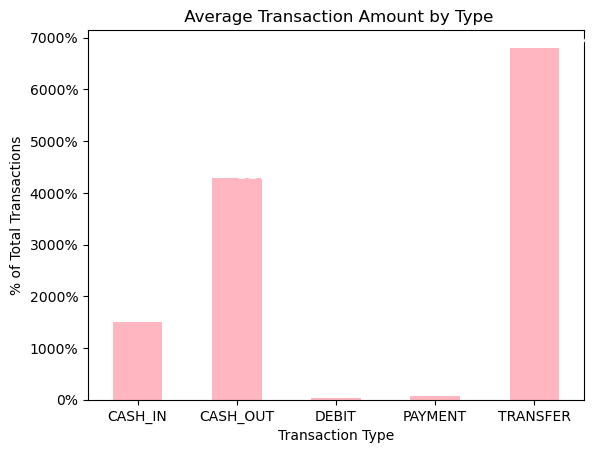

In [16]:
colors = ['lightpink']
avg_transaction_amount = df['amount'].groupby(df['type']).mean()
ax = (avg_transaction_amount * 100.0 / len(df)).plot(
    kind='bar',
    stacked=True,
    rot=0,
    color=colors
)

ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('% of Total Transactions')
ax.set_xlabel('Transaction Type')
ax.set_title(' Average Transaction Amount by Type')

# Iterate over the bar heights and add labels to the bars
total = avg_transaction_amount.sum()
for bar, count in zip(ax.patches, avg_transaction_amount):
    percentage = count / total * 100
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() - 3.5,
            f'{percentage:.1f}%',
            fontsize=12,
            color='white',
            weight='bold'
           )

plt.show()

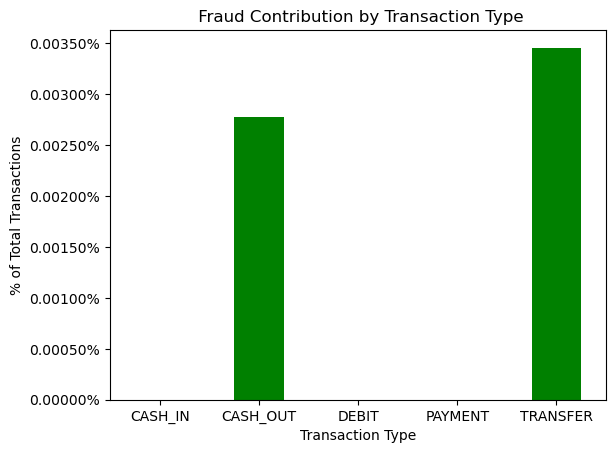

In [17]:
colors = ['green']
fraud_contribution_by_type = df['isFraud'].groupby(df['type']).mean()
ax = (fraud_contribution_by_type * 100.0 / len(df)).plot(
    kind='bar',
    stacked=True,
    rot=0,
    color=colors
)

ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('% of Total Transactions')
ax.set_xlabel('Transaction Type')
ax.set_title(' Fraud Contribution by Transaction Type')

plt.show()

# Iterate over the bar heights and add labels to the bars

total = fraud_contribution_by_type.sum()
for bar, count in zip(ax.patches, fraud_contribution_by_type):
    percentage = count / total * 100
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() - 3.5,
            f'{percentage:.1f}%',
            fontsize=12,
            color='white',
            weight='bold'
           )

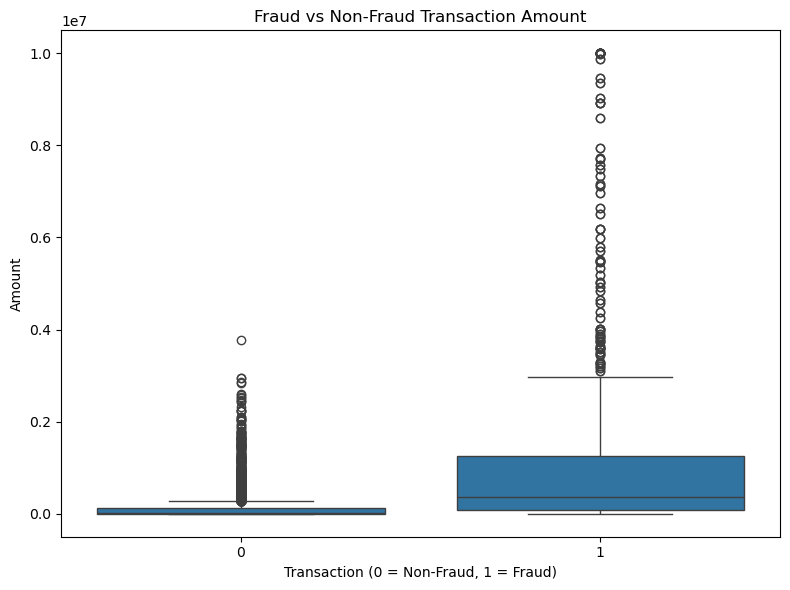

In [18]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="isFraud", y="amount")

plt.title("Fraud vs Non-Fraud Transaction Amount")
plt.xlabel("Transaction (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Amount")
plt.tight_layout()
plt.show()

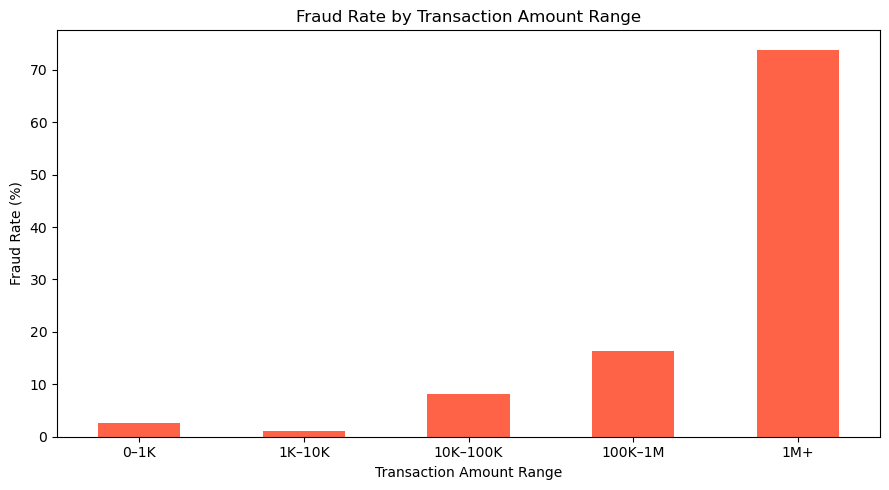

In [19]:
# Create transaction amount ranges
bins = [0, 1_000, 10_000, 100_000, 1_000_000, float("inf")]
labels = ["0–1K", "1K–10K", "10K–100K", "100K–1M", "1M+"]

df["amount_range"] = pd.cut(
    df["amount"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate fraud rate within each range
fraud_rate = df.groupby("amount_range", observed=False)["isFraud"].mean() * 100

# Plot
fraud_rate.plot(kind="bar", color="tomato", figsize=(9, 5))
plt.title("Fraud Rate by Transaction Amount Range")
plt.xlabel("Transaction Amount Range")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


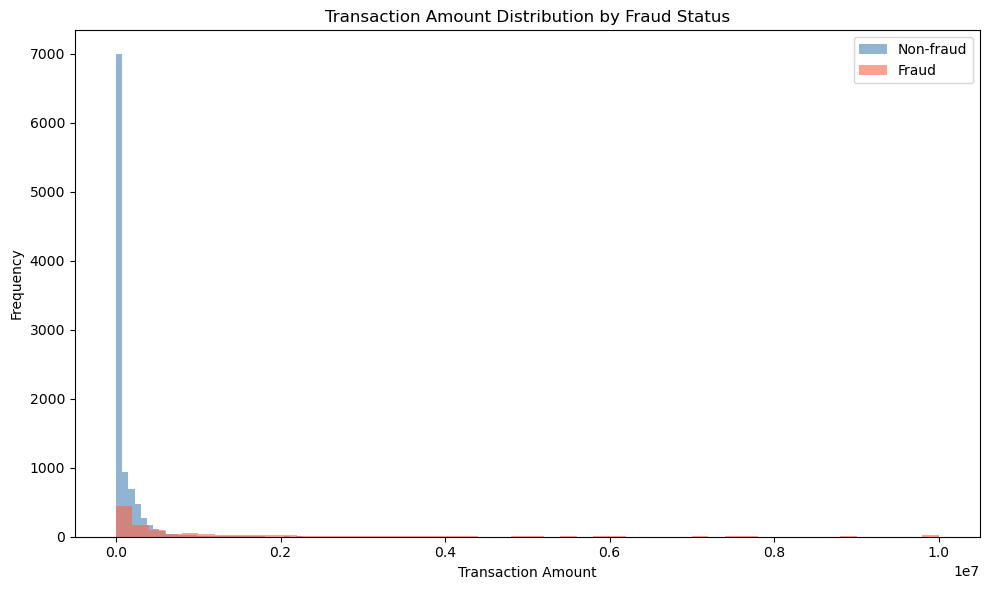

In [20]:
non_fraud = df.loc[df["isFraud"] == 0, "amount"]
fraud = df.loc[df["isFraud"] == 1, "amount"]

plt.figure(figsize=(10, 6))
plt.hist(non_fraud, bins=50, alpha=0.6, label="Non-fraud", color="steelblue")
plt.hist(fraud, bins=50, alpha=0.6, label="Fraud", color="tomato")

plt.title("Transaction Amount Distribution by Fraud Status")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

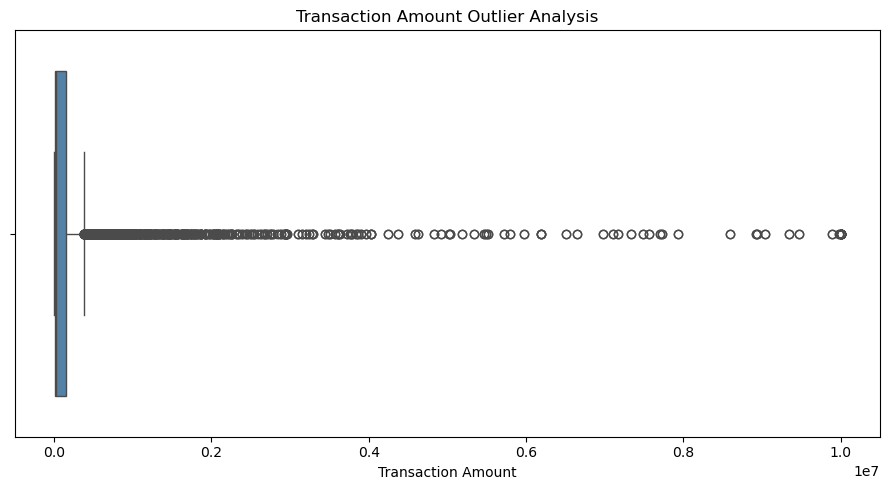

In [21]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="amount", color="steelblue")

plt.title("Transaction Amount Outlier Analysis")
plt.xlabel("Transaction Amount")
plt.tight_layout()
plt.show()

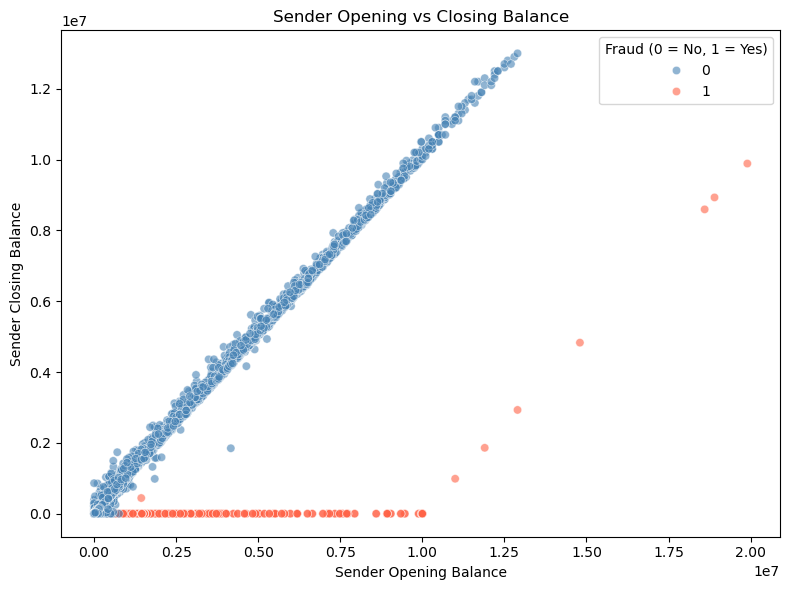

In [22]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="oldbalanceOrg",
    y="newbalanceOrig",
    hue="isFraud",
    alpha=0.6,
    palette={0: "steelblue", 1: "tomato"}
)

plt.title("Sender Opening vs Closing Balance")
plt.xlabel("Sender Opening Balance")
plt.ylabel("Sender Closing Balance")
plt.legend(title="Fraud (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()

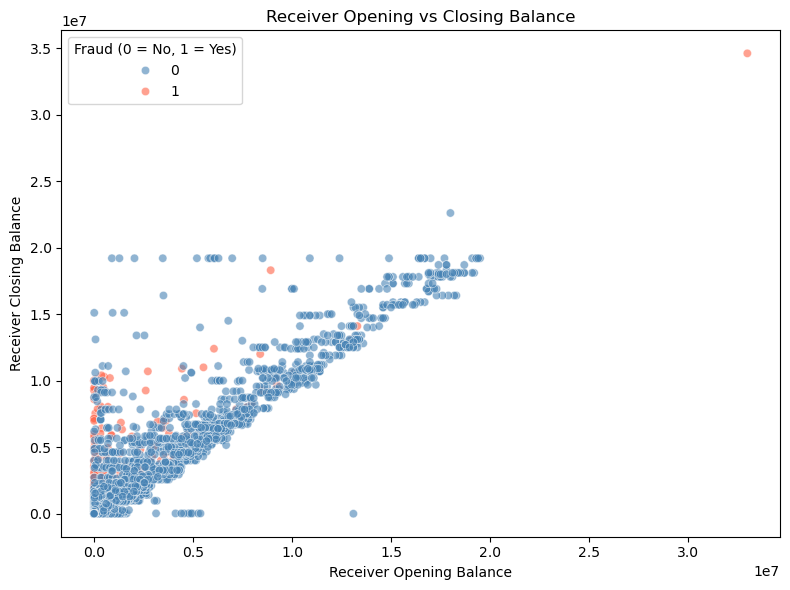

In [23]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="oldbalanceDest",
    y="newbalanceDest",
    hue="isFraud",
    alpha=0.6,
    palette={0: "steelblue", 1: "tomato"}
)

plt.title("Receiver Opening vs Closing Balance")
plt.xlabel("Receiver Opening Balance")
plt.ylabel("Receiver Closing Balance")
plt.legend(title="Fraud (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()


In [24]:
#sender_balance_change
df["sender_balance_change"] = df["oldbalanceOrg"] - df["newbalanceOrig"]
#receiver_balance_change
df["receiver_balance_change"] = df["newbalanceDest"] - df["oldbalanceDest"]
#balance_mismatch_sender
df["balance_mismatch_sender"] = (
    df["sender_balance_change"] - df["amount"]
).abs()

#balance_mismatch_receiver
df["balance_mismatch_receiver"] = (
    df["receiver_balance_change"] - df["amount"]
).abs()
#balance_mismatch
df["balance_mismatch"] = df["balance_mismatch_sender"] + df["balance_mismatch_receiver"]
#transaction_to_balance_ratio
df["transaction_to_balance_ratio"] = df["amount"] / df["balance_mismatch"].replace(0, np.nan)
#sender_balance_depletion_ratio
df["sender_balance_depletion_ratio"] = df["sender_balance_change"] / df["oldbalanceOrg"].replace(0, np.nan)
#transaction_amount_category
df["transaction_amount_category"] = pd.cut(df["amount"], bins=[0, 100, 1000, 10000, np.inf], labels=["low", "medium", "high", "very high"])
#sender_zero_balance
df["sender_zero_balance"] = (df["newbalanceOrig"] == 0).astype(int)
#receiver_zero_balance
df["receiver_zero_balance"] = (df["newbalanceDest"] == 0).astype(int)

In [25]:
df

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,...,sender_balance_change,receiver_balance_change,balance_mismatch_sender,balance_mismatch_receiver,balance_mismatch,transaction_to_balance_ratio,sender_balance_depletion_ratio,transaction_amount_category,sender_zero_balance,receiver_zero_balance
0,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,...,181.00,0.00,0.000000e+00,181.00,181.00,1.000000,1.000000,medium,1,1
1,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.00,0.00,1,...,181.00,-21182.00,0.000000e+00,21363.00,21363.00,0.008473,1.000000,medium,1,1
2,1,TRANSFER,2806.00,C1420196421,2806.00,0.00,C972765878,0.00,0.00,1,...,2806.00,0.00,0.000000e+00,2806.00,2806.00,1.000000,1.000000,high,1,1
3,1,CASH_OUT,2806.00,C2101527076,2806.00,0.00,C1007251739,26202.00,0.00,1,...,2806.00,-26202.00,0.000000e+00,29008.00,29008.00,0.096732,1.000000,high,1,1
4,1,TRANSFER,20128.00,C137533655,20128.00,0.00,C1848415041,0.00,0.00,1,...,20128.00,0.00,0.000000e+00,20128.00,20128.00,1.000000,1.000000,very high,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11137,7,DEBIT,6393.71,C1331144930,433084.38,426690.68,C684896216,478421.00,210535.25,0,...,6393.70,-267885.75,1.000000e-02,274279.46,274279.47,0.023311,0.014763,high,0,0
11138,7,CASH_OUT,298799.54,C932023579,426690.68,127891.14,C1761353343,704355.36,5270364.19,0,...,298799.54,4566008.83,0.000000e+00,4267209.29,4267209.29,0.070022,0.700272,very high,0,0
11139,7,CASH_OUT,423159.63,C61395726,127891.14,0.00,C1298316171,610479.00,749621.53,0,...,127891.14,139142.53,2.952685e+05,284017.10,579285.59,0.730485,1.000000,very high,1,0
11140,7,PAYMENT,1094.03,C1224570697,13918.00,12823.97,M983553548,0.00,0.00,0,...,1094.03,0.00,6.821210e-13,1094.03,1094.03,1.000000,0.078605,high,0,1


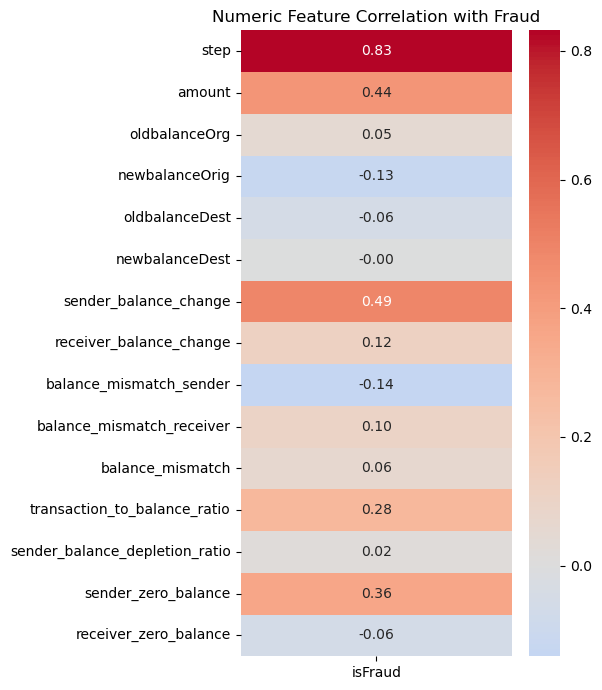

In [26]:
numeric = df.select_dtypes(include="number")
fraud_corr = numeric.corr()[["isFraud"]].drop("isFraud")

plt.figure(figsize=(6, 7))
sns.heatmap(fraud_corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")

plt.title("Numeric Feature Correlation with Fraud")
plt.tight_layout()
plt.show()

In [27]:
df2 = df.copy()

In [28]:
df2

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,...,sender_balance_change,receiver_balance_change,balance_mismatch_sender,balance_mismatch_receiver,balance_mismatch,transaction_to_balance_ratio,sender_balance_depletion_ratio,transaction_amount_category,sender_zero_balance,receiver_zero_balance
0,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,...,181.00,0.00,0.000000e+00,181.00,181.00,1.000000,1.000000,medium,1,1
1,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.00,0.00,1,...,181.00,-21182.00,0.000000e+00,21363.00,21363.00,0.008473,1.000000,medium,1,1
2,1,TRANSFER,2806.00,C1420196421,2806.00,0.00,C972765878,0.00,0.00,1,...,2806.00,0.00,0.000000e+00,2806.00,2806.00,1.000000,1.000000,high,1,1
3,1,CASH_OUT,2806.00,C2101527076,2806.00,0.00,C1007251739,26202.00,0.00,1,...,2806.00,-26202.00,0.000000e+00,29008.00,29008.00,0.096732,1.000000,high,1,1
4,1,TRANSFER,20128.00,C137533655,20128.00,0.00,C1848415041,0.00,0.00,1,...,20128.00,0.00,0.000000e+00,20128.00,20128.00,1.000000,1.000000,very high,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11137,7,DEBIT,6393.71,C1331144930,433084.38,426690.68,C684896216,478421.00,210535.25,0,...,6393.70,-267885.75,1.000000e-02,274279.46,274279.47,0.023311,0.014763,high,0,0
11138,7,CASH_OUT,298799.54,C932023579,426690.68,127891.14,C1761353343,704355.36,5270364.19,0,...,298799.54,4566008.83,0.000000e+00,4267209.29,4267209.29,0.070022,0.700272,very high,0,0
11139,7,CASH_OUT,423159.63,C61395726,127891.14,0.00,C1298316171,610479.00,749621.53,0,...,127891.14,139142.53,2.952685e+05,284017.10,579285.59,0.730485,1.000000,very high,1,0
11140,7,PAYMENT,1094.03,C1224570697,13918.00,12823.97,M983553548,0.00,0.00,0,...,1094.03,0.00,6.821210e-13,1094.03,1094.03,1.000000,0.078605,high,0,1


In [29]:
df2.dtypes

step                                 int64
type                                object
amount                             float64
nameOrig                            object
oldbalanceOrg                      float64
newbalanceOrig                     float64
nameDest                            object
oldbalanceDest                     float64
newbalanceDest                     float64
isFraud                              int64
amount_range                      category
sender_balance_change              float64
receiver_balance_change            float64
balance_mismatch_sender            float64
balance_mismatch_receiver          float64
balance_mismatch                   float64
transaction_to_balance_ratio       float64
sender_balance_depletion_ratio     float64
transaction_amount_category       category
sender_zero_balance                  int64
receiver_zero_balance                int64
dtype: object

In [30]:
df2 = df2.drop(columns=[
    "nameOrig", "nameDest",
    "transaction_to_balance_ratio", "sender_balance_depletion_ratio",
    "step",
    "newbalanceOrig", "newbalanceDest",
    "sender_balance_change", "receiver_balance_change",
    "balance_mismatch_sender", "balance_mismatch_receiver", "balance_mismatch",
    "sender_zero_balance", "receiver_zero_balance"
])

In [31]:
print(df2.columns.tolist())

['type', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'isFraud', 'amount_range', 'transaction_amount_category']


In [32]:
df2 = pd.get_dummies(
    df2,
    columns=["type", "amount_range", "transaction_amount_category"],
    dtype=int
)


In [33]:
df2

,amount,oldbalanceOrg,oldbalanceDest,isFraud,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,amount_range_0–1K,amount_range_1K–10K,amount_range_10K–100K,amount_range_100K–1M,amount_range_1M+,transaction_amount_category_low,transaction_amount_category_medium,transaction_amount_category_high,transaction_amount_category_very high
0,181.00,181.00,0.00,1,0,0,0,0,1,1,0,0,0,0,0,1,0,0
1,181.00,181.00,21182.00,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0
2,2806.00,2806.00,0.00,1,0,0,0,0,1,0,1,0,0,0,0,0,1,0
3,2806.00,2806.00,26202.00,1,0,1,0,0,0,0,1,0,0,0,0,0,1,0
4,20128.00,20128.00,0.00,1,0,0,0,0,1,0,0,1,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11137,6393.71,433084.38,478421.00,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0
11138,298799.54,426690.68,704355.36,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1
11139,423159.63,127891.14,610479.00,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1
11140,1094.03,13918.00,0.00,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0


In [34]:
#logistic regression# We will use the data frame where we had created dummy variables

y = df2['isFraud'].values
X = df2.drop(columns=['isFraud'])
features = X.columns.values


In [35]:
# Scaling all the variables to a range of 0 to 1

from sklearn.preprocessing import MinMaxScaler

features = X.columns.values
scaler = MinMaxScaler(feature_range = (0,1))
scaler.fit(X)
X = pd.DataFrame(scaler.transform(X))
X.columns = features

In [36]:
# Create Train & Test Data

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [37]:
# Running logistic regression model

from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
result = model.fit(X_train, y_train)

In [38]:
from sklearn import metrics
prediction_test = model.predict(X_test)

# Print the prediction accuracy

print (metrics.accuracy_score(y_test, prediction_test))

0.9198324857912055


In [39]:
#random forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)
model_rf = RandomForestClassifier(n_estimators=1000, oob_score=True, n_jobs=-1, random_state=50, max_leaf_nodes=30)
model_rf.fit(X_train, y_train)

# Make predictions

prediction_test = model_rf.predict(X_test)
print(metrics.accuracy_score(y_test, prediction_test))

0.9798115746971736


<Axes: >

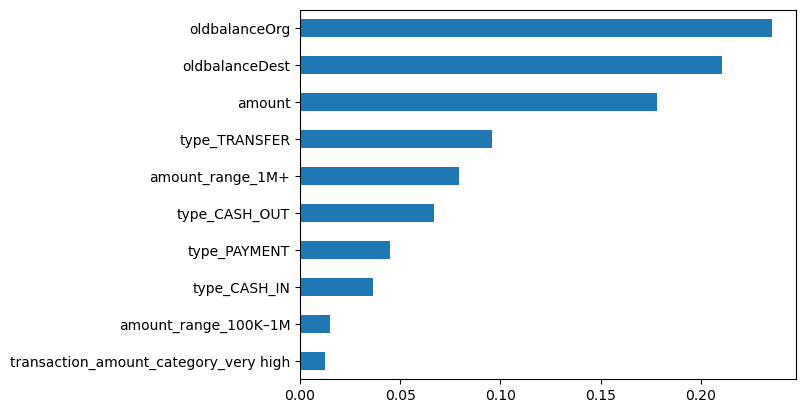

In [40]:
importances = model_rf.feature_importances_
weights = pd.Series(importances,
                 index=X.columns.values)
weights.sort_values()[-10:].plot(kind = 'barh')

In [41]:
#support vector machine
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [42]:
from sklearn.svm import SVC

model.svm = SVC(kernel='linear') 
model.svm.fit(X_train,y_train)
preds = model.svm.predict(X_test)
metrics.accuracy_score(y_test, preds)

0.9198324857912055

In [43]:
# Create the Confusion matrix
from sklearn.metrics import classification_report, confusion_matrix  
print(confusion_matrix(y_test,preds))

[[2978   18]
 [ 250   97]]


In [44]:

# AdaBoost Algorithm
from sklearn.ensemble import AdaBoostClassifier
model = AdaBoostClassifier()
# n_estimators = 50 (default value) 
# base_estimator = DecisionTreeClassifier (default value)
model.fit(X_train,y_train)
preds = model.predict(X_test)
metrics.accuracy_score(y_test, preds)

0.9679928208196231

In [45]:
#XG boost
from xgboost import XGBClassifier
model = XGBClassifier()
model.fit(X_train, y_train)
preds = model.predict(X_test)
metrics.accuracy_score(y_test, preds)

0.9898294944660485

In [46]:
import joblib

# Save trained XGBoost model
joblib.dump(model, 'random_forest_model.joblib')

# Save scaler
joblib.dump(scaler, 'scaler.joblib')

# Save feature columns
joblib.dump(X.columns.tolist(), 'feature_columns.joblib')

print("All files saved successfully!")

All files saved successfully!


In [47]:
print(data.shape)                                  # record count
print(metrics.accuracy_score(y_test, preds))       # run after the XGBoost cell
print(classification_report(y_test, preds))        # precision, recall, F1

(11142, 10)
0.9898294944660485
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      2996
           1       0.94      0.97      0.95       347

    accuracy                           0.99      3343
   macro avg       0.97      0.98      0.97      3343
weighted avg       0.99      0.99      0.99      3343

